(harmony_batch_correction)=

# Correcting batch effects with Harmony

Single-cell experiments processed on different days, reagent lots, or sequencing runs can
leave technical patterns that separate otherwise similar cells by batch. Batch correction
reduces that structure so biological differences are easier to examine. CyteArc implements the
Harmony2 algorithm of [Patikas et al. (2026)](https://doi.org/10.64898/2026.03.16.711825), which
builds on the original Harmony of [Korsunsky et al. (2019)](https://doi.org/10.1038/s41592-019-0619-0).
Harmony iteratively adjusts PCA coordinates to encourage mixing of comparable cells across batches without
modifying the underlying counts; the corrected coordinates then feed the neighbour graph and everything downstream. Better mixing is only useful if meaningful biological differences survive, as overcorrecting can also occur.

This tutorial compares one uncorrected RNA analysis with the same analysis after Harmony,
using the Binvignat rheumatoid arthritis PBMC dataset ([CELLxGENE collection](https://cellxgene.cziscience.com/collections/e1a9ca56-f2ee-435d-980a-4f49ab7a952b),
[JCI Insight](https://insight.jci.org/articles/view/178499)). It constructs equal cell counts for each sequencing-batch and disease combination so technical mixing can be assessed without making disease identical to batch; this sampling is not a donor-balanced biological design.

First choose comparable cells, then run the pipeline twice, adding
`harmony_batch_columns=["batch"]` to the second run.

The code downloads the [versioned H5AD file](https://datasets.cellxgene.cziscience.com/3b751975-34bb-409a-a9b7-98380f0450ea.h5ad) to local disk, converts it to a Zarr store, and runs the analysis locally; `urlretrieve` transfers the file only and does not make CyteArc compute the data remotely. [](remote_stores.ipynb) covers the workflow for remote datasets.

## Prepare the local source store

Download the H5AD file only when it is absent. Inspecting it before conversion makes the matrix choice and dimensions explicit. This tutorial requires the integer-like count matrix at `raw/X` with 108,717 cells and 21,648 features.

In [1]:
# Load tools for downloading, converting, and comparing the example data.
from os import environ
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlretrieve

import numpy as np
import pandas as pd

import cytearc

# Keep routine progress messages out of the teaching output.
cytearc.configure_output(level="ERROR", progress=False)

Started: 2026-10-22T16:51:48.984584Z | Wall time: 0.495 s

Choose local paths for the reusable download and converted counts.

In [2]:
# Choose a local folder for reusable input files.
dataset_directory = Path(environ.get("CYTEARC_DOCS_DATA_DIR", "cytearc_datasets"))

# Create the local folder if it does not already exist.
dataset_directory.mkdir(parents=True, exist_ok=True)

# Use the versioned H5AD file from the published collection.
download_url = (
    "https://datasets.cellxgene.cziscience.com/"
    "3b751975-34bb-409a-a9b7-98380f0450ea.h5ad"
)

# Name the local H5AD download.
h5ad_path = dataset_directory / "binvignat_ra_pbmc.h5ad"

# Name the reusable converted count store.
source_store = dataset_directory / "binvignat_ra_pbmc.zarr"

# Reuse completed local work when it is already present.
if not h5ad_path.exists():

    # Use a temporary filename until the download finishes.
    partial_path = h5ad_path.with_suffix(".h5ad.part")

    # Download the complete input file to the temporary filename.
    urlretrieve(download_url, partial_path)

    # Move the completed file or store to its reusable path.
    partial_path.replace(h5ad_path)

Started: 2026-10-22T16:51:49.482275Z | Wall time: 1.005 s

Check that the file contains the expected counts before converting it:

In [3]:
# Inspect the available count matrix before conversion.
inspection = cytearc.inspect_h5ad(str(h5ad_path))

# Verify that the count matrix is stored at raw/X.
assert inspection.matrixKey == "raw/X"

# Verify that the matrix contains integer-like counts.
assert inspection.integerLike is True

# Verify the published cell and gene counts.
assert (inspection.nCells, inspection.nFeatures) == (108_717, 21_648)

# Show the count matrix and dimensions needed for conversion.
{
    "count matrix": inspection.matrixKey,
    "cells": inspection.nCells,
    "genes": inspection.nFeatures,
    "integer counts": inspection.integerLike,
}

{'count matrix': 'raw/X',
 'cells': 108717,
 'genes': 21648,
 'integer counts': True}

Started: 2026-10-22T16:51:50.489223Z | Wall time: 0.518 s

Convert once and keep the source store for later sessions. This dataset needs a 6 GB import
budget for the default count layout. The temporary directory keeps an interrupted conversion
separate from the finished store.

In [4]:
# Reuse completed local work when it is already present.
if not source_store.exists():

    # Stage conversion in a temporary folder before publishing the completed store.
    with TemporaryDirectory(dir=dataset_directory) as conversion_directory:

        # Convert into a temporary store until every write succeeds.
        staged_store = Path(conversion_directory) / source_store.name

        # Read the count matrix and its cell and feature identifiers.
        reader = cytearc.H5adReader.from_inspect(inspection)

        # Ensure the input reader is closed even if conversion fails.
        try:

            # Write the prepared counts and metadata to the new store.
            cytearc.H5adToZarr(
                reader,
                zarr_loc=str(staged_store),
                nthreads=4,

                # The default count layout of these 108,717 cells plans for about 5 GB.
                mem_budget="6G",
            ).dump()
        finally:

            # Close the H5AD reader after conversion.
            reader.h5.close()

        # Move the completed file or store to its reusable path.
        staged_store.replace(source_store)

Started: 2026-10-22T16:51:51.008839Z | Wall time: 18.120 s

Initialize the source with `min_features_per_cell=0`, which drops only cells without detected
features (none here), so the imported cell axis stays intact while the tutorial defines its own
exact selection.

In [5]:
# Open the source without dropping cells before selecting the cohort.
source = cytearc.DataStore(
    str(source_store), default_assay="RNA", min_features_per_cell=0, nthreads=4
)

# Check the initialized count matrix dimensions.
{"cells": source.cells.N, "genes": source.RNA.feats.N}

{'cells': 108717, 'genes': 21648}

Started: 2026-10-22T16:52:09.132443Z | Wall time: 1.496 s

Mount the source into a temporary writable analysis store. Count matrices remain in the local
source store, while the selection and pipeline artifacts are written below the temporary
directory. Keep `analysis_directory` bound for as long as the mounted datastore is in use.

In [6]:
# Keep new analysis results in a temporary working folder.
analysis_directory = TemporaryDirectory()

# Choose the path for the writable working store.
analysis_store = Path(analysis_directory.name) / "ra_batch_demo.zarr"

# Open the datastore for the following analysis.
ds = cytearc.mount_datastore(
    str(source_store),
    at=str(analysis_store),
    default_assay="RNA",
    min_features_per_cell=0,
    nthreads=4,
)

# Check that mounting preserved the source dimensions.
{
    "same cell count": ds.cells.N == source.cells.N,
    "same gene count": ds.RNA.feats.N == source.RNA.feats.N,
}

{'same cell count': True, 'same gene count': True}

Started: 2026-10-22T16:52:10.630368Z | Wall time: 1.627 s

## Create a balanced 9,000-cell analysis

We will compare corrections on a smaller subset of 9,000 cells. The source contains three
batches and two disease groups. Selecting 1,500 cells from every batch and disease
combination gives both disease groups equal representation within each batch. One seeded
generator makes the resulting `docs_ra_batch_demo` selection reproducible from the same
source file.

In [7]:
# Read the sequencing-batch label for each cell.
batch = ds.cells.fetch_all("batch").astype(str)

# Read each cell's biological condition.
disease = ds.cells.fetch_all("disease").astype(str)

# List the distinct sequencing batches.
batch_values = np.unique(batch)

# List the distinct biological conditions.
disease_values = np.unique(disease)

# Require the expected three sequencing batches.
assert batch_values.size == 3

# Require the expected two biological conditions.
assert disease_values.size == 2

# Compare the cell counts or fractions across the selected groups.
pd.crosstab(batch, disease, rownames=["batch"], colnames=["condition"])

condition,normal,rheumatoid arthritis
batch,,
1,19011,21639
2,17989,8043
3,23080,18955


Started: 2026-10-22T16:52:12.259778Z | Wall time: 0.072 s

Draw the same number of cells from each batch and disease group.

In [8]:
# Seed the generator so this example is reproducible.
rng = np.random.default_rng(42)

# Start with no cells selected.
selected = np.zeros(ds.cells.N, dtype=bool)

# Sample every sequencing batch with the same disease balance.
for batch_value in batch_values:

    # Choose an equal-sized sample from this disease group.
    for disease_value in disease_values:

        # Find cells in this batch and disease combination.
        candidates = np.flatnonzero((batch == batch_value) & (disease == disease_value))

        # Require enough cells to draw 1,500 without replacement.
        assert candidates.size >= 1_500

        # Draw the same number of cells from this group.
        chosen = rng.choice(candidates, size=1_500, replace=False)

        # Add the sampled cells to the shared selection.
        selected[chosen] = True

# Check that balanced sampling retained exactly 9,000 cells.
assert selected.sum() == 9_000

# Save the values in cell metadata using the stated selection.
ds.cells.insert(column_name="docs_ra_batch_demo", values=selected, overwrite=True)

# Compare the cell counts or fractions across the selected groups.
pd.crosstab(
    batch[selected], disease[selected], rownames=["batch"], colnames=["condition"]
)

condition,normal,rheumatoid arthritis
batch,,
1,1500,1500
2,1500,1500
3,1500,1500


Started: 2026-10-22T16:52:12.333092Z | Wall time: 0.034 s

The constructed subset has equal cell counts for every batch and disease combination, but donor
representation is not balanced, and equal condition counts do not guarantee comparable cell-type
composition within each batch. Disease is a biological condition rather than a technical
covariate, so only `batch` is supplied to Harmony below. If each condition occurred in a different
batch, these data alone could not tell a disease effect from a batch effect; correction would not
resolve that study-design problem.

(harmony)=

## Run matched uncorrected and Harmony pipelines

Both runs use the same cells and the default feature count, PCA dimensions, and neighbour count.
The only analysis difference is `harmony_batch_columns=["batch"]` in the second run.
We turn off filtering because we already chose the cells, and skip clustering, cell-cycle scores,
doublet detection, and markers because this comparison only needs the graph and UMAP.

In [9]:
# Keep the cells and analysis settings identical in both runs.
pipeline_options = {
    "cell_key": "docs_ra_batch_demo",
    "filtering": False,
    "leiden": False,
    "cell_cycle": False,
    "paris": False,
    "doublets": False,
    "markers": False,
    "snapshot_columns": ("batch", "disease", "rough_annot"),
}

Started: 2026-10-22T16:52:12.369226Z | Wall time: 0.004 s

Run the uncorrected analysis with these shared settings.

In [10]:
# Run the baseline without batch correction.
uncorrected = ds.pipeline.run(label="ra_uncorrected", **pipeline_options)

# Check the cell count used by the uncorrected run.
{"analysis cells": int(uncorrected.cells.fetch_all("I").sum())}

{'analysis cells': 9000}

Started: 2026-10-22T16:52:12.374833Z | Wall time: 43.263 s

Repeat the analysis with batch correction.

In [11]:
# Run the same analysis with sequencing batch supplied to Harmony.
harmony = ds.pipeline.run(
    label="ra_harmony", harmony_batch_columns=["batch"], **pipeline_options
)

# Check that the corrected run uses the same cell count.
{"analysis cells": int(harmony.cells.fetch_all("I").sum())}

{'analysis cells': 9000}

Started: 2026-10-22T16:52:55.640076Z | Wall time: 15.947 s

Harmony adjusts PCA coordinates before the neighbour graph is built. It does not change the count
matrix. The two frozen runs keep the exact selections, metadata, layouts, and graph artifacts used
for the comparison.

## Compare the layouts

Plot each run by sequencing batch and by the imported broad annotation. Look for better mixing
of batches while the broad cell types remain distinct.

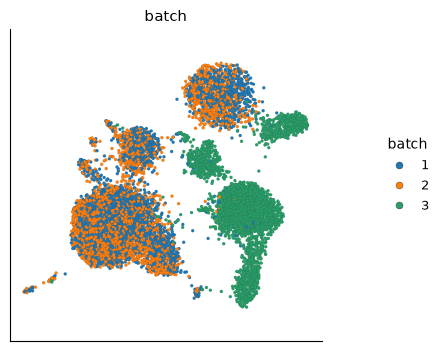

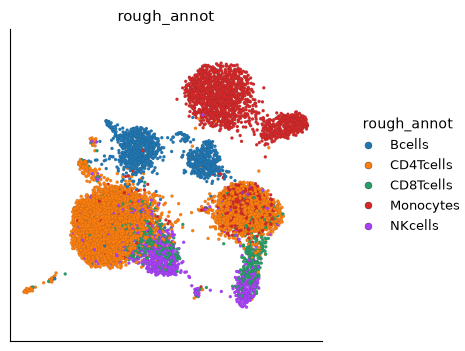

Started: 2026-10-22T16:53:11.588975Z | Wall time: 1.103 s

In [12]:
# Inspect batch separation before correction.
ds.plots.embedding(run=uncorrected, color_by="batch")

# Inspect cell-type structure before correction.
ds.plots.embedding(run=uncorrected, color_by="rough_annot")

Before correction, batch 3 occupies several regions apart from batches 1 and 2.

The Harmony result:

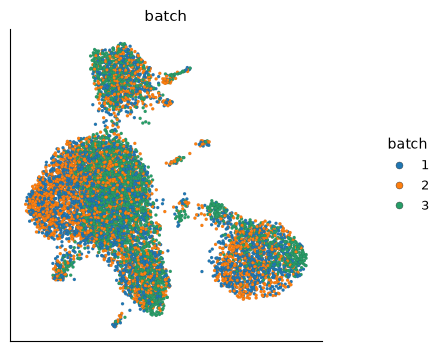

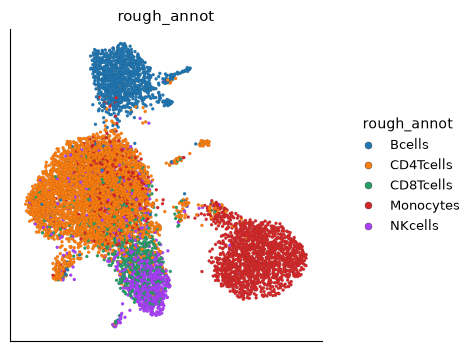

Started: 2026-10-22T16:53:12.694323Z | Wall time: 0.482 s

In [13]:
# Inspect batch mixing after Harmony correction.
ds.plots.embedding(run=harmony, color_by="batch")

# Check whether broad cell-type structure remains after correction.
ds.plots.embedding(run=harmony, color_by="rough_annot")

After correction, the three batches overlap more within the major groups, while B cells
and monocytes remain distinct from the T-cell and NK-cell region. Use the metrics below
to assess this visual comparison on the graph.

(lisi_metrics)=

## Quantify mixing and structural preservation

iLISI asks how many batches occur in a cell's neighbourhood and how evenly they are
represented. Higher values indicate more local batch mixing. A neighbourhood drawn evenly from
all three batches is more diverse than one dominated by a single batch. That does not mean every
cell type should mix equally when its abundance differs by batch. cLISI applies the same
diversity calculation to the cell-type labels in `rough_annot`, but here mixing different
cell types is not the goal. CyteArc inverts and scales cLISI so higher values indicate
better separation of those annotations.

Graph connectivity asks whether cells sharing an annotation remain connected. All three
reported scores use the convention that higher is better, but they answer different
questions. Use the exact neighbour and connectivity artifacts from each run. The LISI
metrics choose their neighbourhood scale from the neighbour count by default.

In [14]:
# Measure batch mixing and annotation preservation for one run.
def integration_diagnostics(run):
    return {
        "iLISI (batch)": ds.integration.compute_ilisi(
            batch_colname="batch", neighbors=run["neighbors"]
        ),
        "cLISI (rough_annot)": ds.integration.compute_clisi(
            annotation_column="rough_annot", neighbors=run["neighbors"]
        ),
        "graph connectivity (rough_annot)": ds.integration.compute_graph_connectivity(
            annotation_column="rough_annot", graph=run["connectivity_map"]
        ),
    }

Started: 2026-10-22T16:53:13.178762Z | Wall time: 0.004 s

Calculate the same diagnostics for both completed runs.

In [15]:
# Collect the mixing and preservation metrics for both runs.
score_frame = pd.DataFrame(
    {
        "Uncorrected": integration_diagnostics(uncorrected),
        "Harmony": integration_diagnostics(harmony),
    }
).T

# Compare mixing and preservation metrics for the two runs.
score_frame.round(3)

,iLISI (batch),cLISI (rough_annot),graph connectivity (rough_annot)
Uncorrected,0.062,0.997,0.952
Harmony,0.216,0.994,0.945


Started: 2026-10-22T16:53:13.184962Z | Wall time: 1.030 s

Read these scores together. Higher iLISI after Harmony, with similar cLISI and graph connectivity,
would support improved technical mixing without obvious loss of broad cell-type structure. These metrics
are diagnostics, not proof that correction is biologically valid or that every disease-associated
signal was preserved. The subset equalizes cell counts, not biological replicates, and disease was
not used as a correction covariate. Biological conclusions still require a donor-aware design and
targeted downstream checks. In particular, compare markers and disease-associated programs
within matched cell types and donors; broad annotation scores can miss changes within a type.

See [Graph construction API reference](/api/graph_construction.html) for the PCA and Harmony contracts, and
[Integration and metrics API reference](/api/integration.html) for the metric definitions.